2104,3,399900
1600,3,329900
2400,3,369000
1416,2,232000
3000,4,539900
1985,4,299900
1534,3,314900
1427,3,198999
1380,3,212000
1494,3,242500
1940,4,239999
2000,3,347000
1890,3,329999
4478,5,699900
1268,3,259900
2300,4,449900
1320,2,299900
1236,3,199900
2609,4,499998
3031,4,599000
1767,3,252900
1888,2,255000
1604,3,242900
1962,4,259900
3890,3,573900
1100,3,249900
1458,3,464500
2526,3,469000
2200,3,475000
2637,3,299900
1839,2,349900
1000,1,169900
2040,4,314900
3137,3,579900
1811,4,285900
1437,3,249900
1239,3,229900
2132,4,345000
4215,4,549000
2162,4,287000
1664,2,368500
2238,3,329900
2567,4,314000
1200,3,299000
852,2,179900
1852,4,299900
1203,3,239500

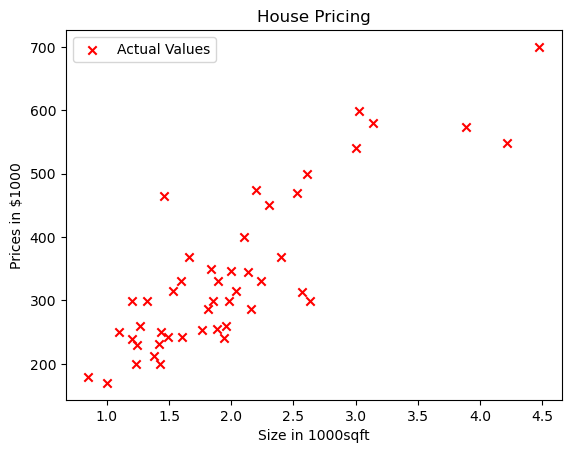

In [474]:
import numpy as np
import matplotlib.pyplot as plt 

x_train = np.array([2.104, 1.6, 2.4, 1.416, 3.0, 1.985, 1.534, 1.427, 1.380, 1.494, 1.940, 2.0, 1.89, 4.478, 1.268, 2.3, 
                    1.32, 1.236, 2.609, 3.031, 1.767, 1.888, 1.604, 1.962, 3.89, 1.1, 1.458, 2.526, 2.2, 2.637, 1.839, 1.0, 2.04,
                    3.137, 1.811, 1.437, 1.239, 2.132, 4.215, 2.162, 1.664, 2.238, 2.567, 1.2, 0.852, 1.852, 1.203])
y_train = np.array([399.9, 329.9, 369.0, 232.0, 539.9, 299.9, 314.9, 198.999, 212.0, 242.5, 239.999, 347.0, 329.999, 699.9, 259.9, 449.9,
                    299.9, 199.9, 499.998, 599.0, 252.9, 255.0, 242.9, 259.9, 573.9, 249.9, 464.5, 469.0, 475.0, 299.9, 349.9, 169.9, 314.9, 579.9,
                    285.9, 249.9, 229.9,345.0, 549.0, 287.0, 368.5, 329.9, 314.0, 299.0, 179.9, 299.9, 239.5])
m = x_train.shape[0]

plt.scatter(x_train, y_train, marker='x', c='r', label="Actual Values")
plt.title("House Pricing")
plt.ylabel("Prices in $1000")
plt.xlabel("Size in 1000sqft")
plt.legend()
plt.show()

In [475]:
def compute_cost(x, y, w, b):
    m = x.shape[0]
    cost = 0.0
    for i in range(m):
        f_wb_i = np.dot(x[i], w) + b
        cost += ((f_wb_i - y[i])**2)
    cost = (1/2*m) * cost
    return cost

In [476]:
def compute_gradient(x, y, w, b):
    m = x.shape[0]
    dj_dw = 0.0
    dj_db = 0.0
    for i in range(m):
        f_wb_i = np.dot(x[i], w) + b
        dj_dw_i = np.dot((f_wb_i - y[i]), x[i])
        dj_db_i = f_wb_i - y[i]
        dj_dw += dj_dw_i
        dj_db += dj_db_i
    dj_dw = dj_dw/m
    dj_db = dj_db/m
    return dj_dw, dj_db

In [477]:
def compute_gradient_descent(x, y, w_in, b_in, alpha, iterations, gradient_function):
    w = w_in
    b = b_in
    for i in range(iterations):
        dj_dw, dj_db = gradient_function(x, y, w, b)
        w = w - np.dot(alpha, dj_dw)
        b = b - np.dot(alpha, dj_db)
    return w, b

In [478]:
w, b = compute_gradient_descent(x_train, y_train, 0, 0, 0.1, 3000, compute_gradient)
print(f"w : {w}\nb : {b}")

w : 134.52528772024172
b : 71.27049244872823


In [479]:
def compute_model_output(x, w, b):
    m=x.shape[0]
    f_wb = np.zeros(m)
    for i in range(m):
        f_wb[i] = w*x[i] + b
    return f_wb

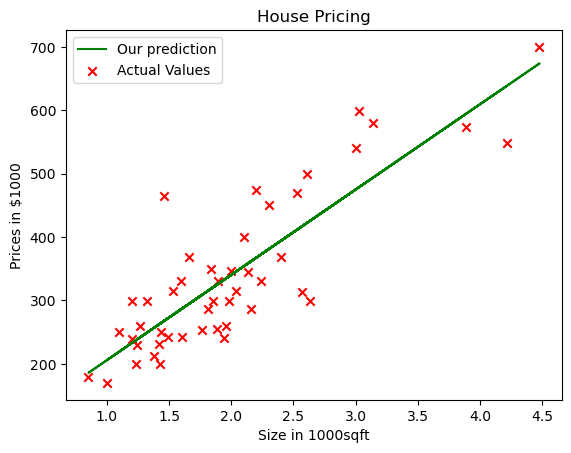

In [480]:
temp_f_wb = compute_model_output(x_train, w, b)
plt.plot(x_train, temp_f_wb, c='g', label="Our prediction")
plt.scatter(x_train, y_train, marker='x', c='r', label="Actual Values")
plt.title("House Pricing")
plt.ylabel("Prices in $1000")
plt.xlabel("Size in 1000sqft")
plt.legend()
plt.show()

In [481]:
x_i = 3.750
cost = w*x_i + b
print(f"${cost} thousand dollars")
# for x_i = 3.750, for alpha = 0.1 and iterations >= 2657 : $575.7403213996347 thousand dollars
# for x_i = 3.750, for alpha = 0.01 and iterations >= 24686 : $575.7403213996414 thousand dollars

$575.7403213996347 thousand dollars


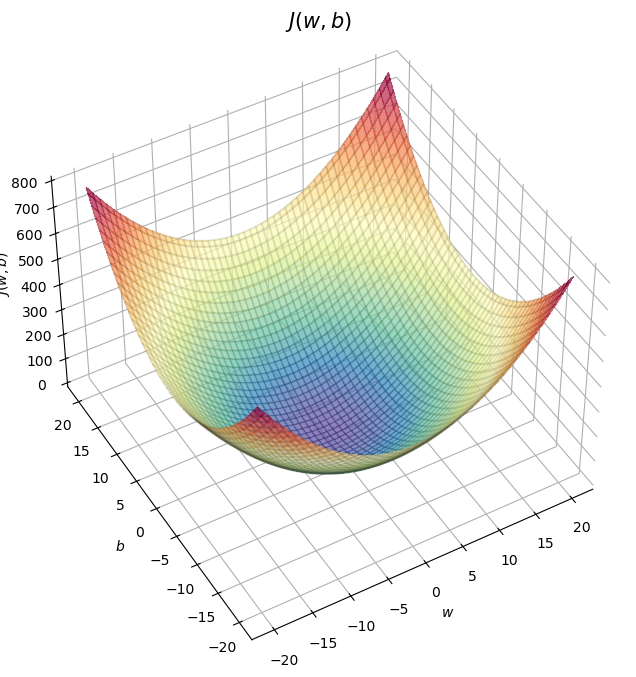

In [482]:
def soup_bowl():
    """ Create figure and plot with a 3D projection"""
    fig = plt.figure(figsize=(8,8))

    #Plot configuration
    ax = fig.add_subplot(111, projection='3d')
    ax.xaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.yaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.zaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.zaxis.set_rotate_label(False)
    ax.view_init(45, -120)

    #Useful linearspaces to give values to the parameters w and b
    w = np.linspace(-20, 20, 100)
    b = np.linspace(-20, 20, 100)

    #Get the z value for a bowl-shaped cost function
    z=np.zeros((len(w), len(b)))
    j=0
    for x in w:
        i=0
        for y in b:
            z[i,j] = x**2 + y**2
            i+=1
        j+=1

    #Meshgrid used for plotting 3D functions
    W, B = np.meshgrid(w, b)

    #Create the 3D surface plot of the bowl-shaped cost function
    ax.plot_surface(W, B, z, cmap = "Spectral_r", alpha=0.7, antialiased=False)
    ax.plot_wireframe(W, B, z, color='k', alpha=0.1)
    ax.set_xlabel("$w$")
    ax.set_ylabel("$b$")
    ax.set_zlabel("$J(w,b)$", rotation=90)
    ax.set_title("$J(w,b)$", size=15)

    plt.show()
soup_bowl()